# Characteristic scales over $(w_0, w_a)$

Braiding ($k_B$) and Jeans ($k_J$) scales today ($z=0$) for a fixed $(c_K, c_B)$, over a grid of
$(w_0, w_a)$ backgrounds. The scales are analytic; CLASS is only run (background only, a fraction of a
second each) to get $\Omega_{m,0}$ of each background with $\theta_s$ fixed.

In [13]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from hiclass_tools import Horndeski, backgrounds_from_class
from hiclass_tools.plotting import use_style

use_style(fontsize=12)

In [14]:
# Configuration
W0 = np.linspace(-1, -0.8, 25)
WA = np.linspace(-1, 0, 25)

CK = 1e4
CB = 1.0
PARAMETRIZATION = 'propto_omega'

WORKERS = None    # parallel CLASS runs (None: all cores)

In [15]:
# Omega_m0 of every background from CLASS (only w0 + wa <= 0)
pairs = [(w0, wa) for w0 in W0 for wa in WA if w0 + wa <= 0]
backgrounds = backgrounds_from_class(pairs, workers=WORKERS)

# Maps on the (wa, w0) grid: rows -> wa, columns -> w0. NaN where there is no valid background
kB_map = np.full((len(WA), len(W0)), np.nan)
kJ_map = np.full((len(WA), len(W0)), np.nan)
Om_map = np.full((len(WA), len(W0)), np.nan)

for (w0, wa), bg in backgrounds.items():
    i, j = np.where(WA == wa)[0][0], np.where(W0 == w0)[0][0]
    model = Horndeski(CK, CB, bg, PARAMETRIZATION)
    kB_map[i, j], kJ_map[i, j], Om_map[i, j] = model.kB(), model.kJ(), bg.Omega_m0

print(f"{len(backgrounds)} / {len(pairs)} backgrounds computed")
print(f"kB in [{np.nanmin(kB_map):.4g}, {np.nanmax(kB_map):.4g}] h/Mpc")
print(f"kJ in [{np.nanmin(kJ_map):.4g}, {np.nanmax(kJ_map):.4g}] h/Mpc")
print(f"Omega_m0 in [{np.nanmin(Om_map):.4f}, {np.nanmax(Om_map):.4f}]")

625 / 625 backgrounds computed
kB in [0.04476, 0.04718] h/Mpc
kJ in [0.02339, 0.03322] h/Mpc
Omega_m0 in [0.2542, 0.3732]


Text(0.5, 0.98, 'Characteristic scales at $z=0$ for $c_K = 1e+04$, $c_B = 1$')

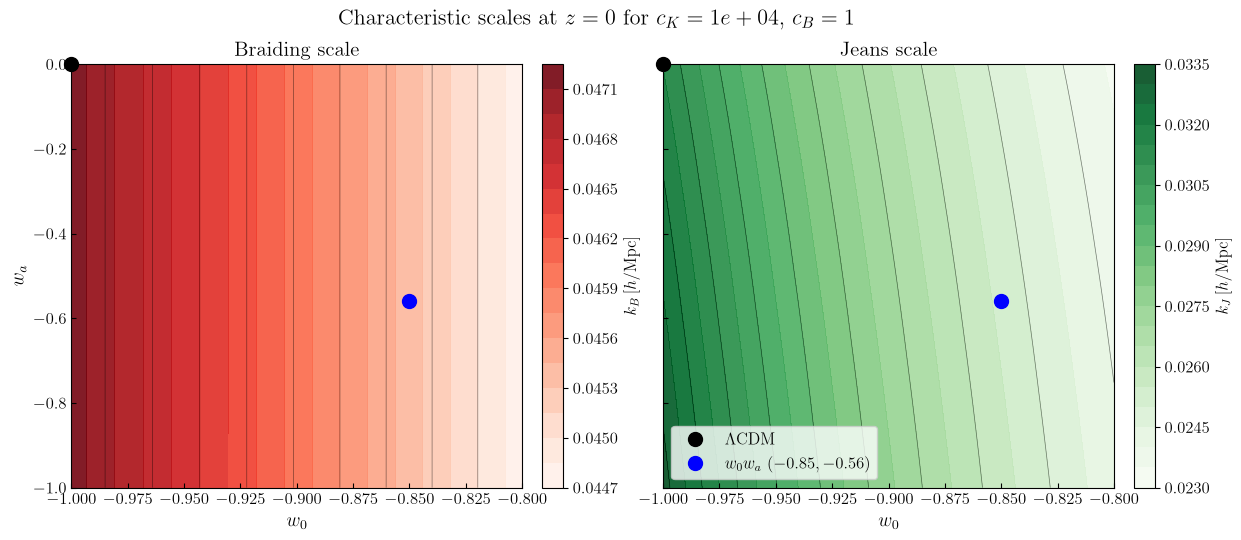

In [16]:
W0_grid, WA_grid = np.meshgrid(W0, WA)

fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)

for ax, values, label, cmap in [(axs[0], kB_map, r'$k_B\,[h/\mathrm{Mpc}]$', 'Reds'),
                                (axs[1], kJ_map, r'$k_J\,[h/\mathrm{Mpc}]$', 'Greens')]:
    contour = ax.contourf(W0_grid, WA_grid, values, levels=20, cmap=cmap, alpha=0.9)
    ax.contour(W0_grid, WA_grid, values, levels=10, colors='k', linewidths=0.5, alpha=0.5)

    cbar = plt.colorbar(contour, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(label)

    # Reference backgrounds
    ax.plot(-1, 0, marker='o', color='k', markersize=10, linestyle='none', label=r'$\Lambda$CDM', clip_on=False, zorder=5)
    ax.plot(-0.85, -0.56, marker='o', color='b', markersize=10, linestyle='none', label=r'$w_0w_a$ $(-0.85, -0.56)$', clip_on=False, zorder=5)

    ax.set_xlabel(r'$w_0$', fontsize=14)
    ax.tick_params(axis='both', which='both', direction='in')

axs[0].set_ylabel(r'$w_a$', fontsize=14)
axs[0].set_title('Braiding scale', fontsize=15)
axs[1].set_title('Jeans scale', fontsize=15)
axs[1].legend(loc='lower left')

fig.suptitle(fr'Characteristic scales at $z=0$ for $c_K = {CK:.3g}$, $c_B = {CB:.3g}$', fontsize=16)

## Dependence on $(c_K, c_B)$

For $c_K \gg 1$ the kinetic term dominates $D = \tfrac{3}{2}\alpha_B^2 + c_K\,\Omega_{DE}$, and both scales grow as
$\sqrt{c_K}$:
$$k_B \simeq \frac{\sqrt{c_K (1 - w_0)}}{c_B}\,\frac{H_0}{c}, \qquad k_J = \frac{aH}{c_s} \propto \sqrt{D} \propto \sqrt{c_K}$$
so $k_B/\sqrt{c_K}$ and $k_J/\sqrt{c_K}$ only depend on $c_B$ and on the background. One map per $c_B$ then covers
every large $c_K$ (the approximation breaks down for $c_K \lesssim 10$, where $\alpha_B^2$ is not negligible).

Text(0.5, 0.95, 'Characteristic scales at $z=0$ normalised by $\\sqrt{c_K}$ (valid for any $c_K \\gg 1$)')

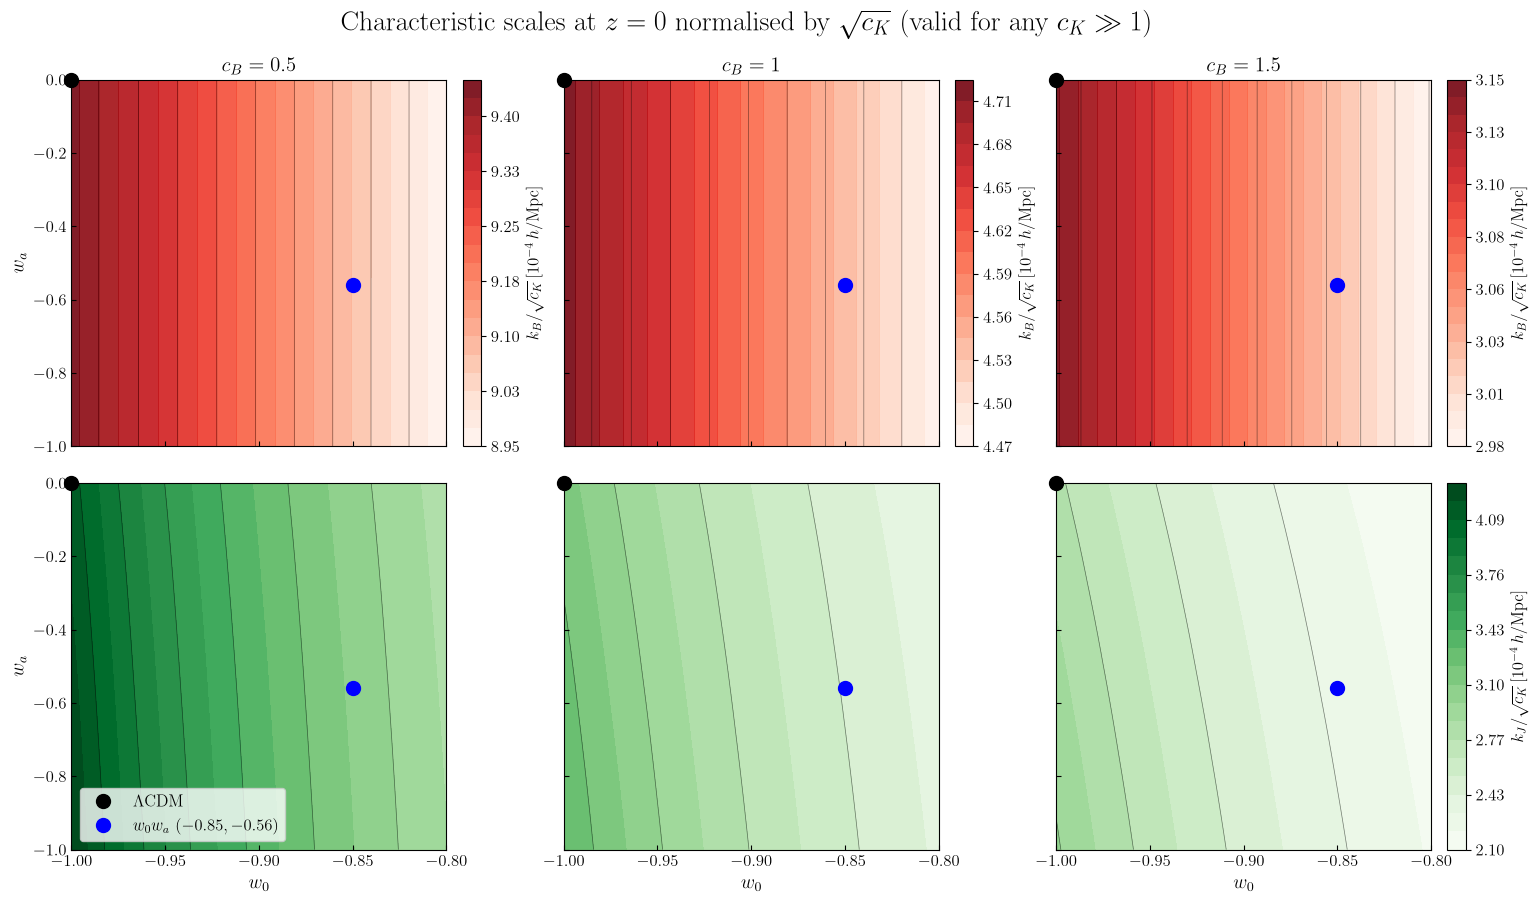

In [17]:
# Normalised scales for several cB (same backgrounds as above, no new CLASS runs)
CB_VALUES = [0.5, 1.0, 1.5]

norm_maps = {name: {cb: np.full((len(WA), len(W0)), np.nan) for cb in CB_VALUES} for name in ['kB', 'kJ']}
for (w0, wa), bg in backgrounds.items():
    i, j = np.where(WA == wa)[0][0], np.where(W0 == w0)[0][0]
    for cb in CB_VALUES:
        model = Horndeski(CK, cb, bg, PARAMETRIZATION)
        norm_maps['kB'][cb][i, j] = model.kB() / np.sqrt(CK) * 1e4   # units of 1e-4 h/Mpc
        norm_maps['kJ'][cb][i, j] = model.kJ() / np.sqrt(CK) * 1e4

fig, axs = plt.subplots(2, len(CB_VALUES), figsize=(6*len(CB_VALUES), 10), sharex=True, sharey=True)
fig.subplots_adjust(hspace=0.1, wspace=0.2)

# kB: one colour scale per panel (it only changes ~5% with the background, but as 1/cB with cB)
for col, cb in enumerate(CB_VALUES):
    ax = axs[0, col]
    contour = ax.contourf(W0_grid, WA_grid, norm_maps['kB'][cb], levels=20, cmap='Reds', alpha=0.9)
    ax.contour(W0_grid, WA_grid, norm_maps['kB'][cb], levels=10, colors='k', linewidths=0.5, alpha=0.5)
    cbar = plt.colorbar(contour, ax=ax, fraction=0.046, pad=0.04, format='%.2f')
    cbar.set_label(r'$k_B/\sqrt{c_K}\,[10^{-4}\,h/\mathrm{Mpc}]$')
    ax.set_title(fr'$c_B = {cb:g}$', fontsize=15)

# kJ: common colour scale for the whole row
kJ_all = np.concatenate([m.ravel() for m in norm_maps['kJ'].values()])
levels_kJ = np.linspace(np.nanmin(kJ_all), np.nanmax(kJ_all), 21)
for col, cb in enumerate(CB_VALUES):
    ax = axs[1, col]
    contour = ax.contourf(W0_grid, WA_grid, norm_maps['kJ'][cb], levels=levels_kJ, cmap='Greens', alpha=1)
    ax.contour(W0_grid, WA_grid, norm_maps['kJ'][cb], levels=levels_kJ[::2], colors='k', linewidths=0.5, alpha=0.5)
    ax.set_xlabel(r'$w_0$', fontsize=14)
    # same colorbar space as the kB row so the columns stay aligned; only the last one is shown
    cbar = plt.colorbar(contour, ax=ax, fraction=0.046, pad=0.04, format='%.2f')
    cbar.set_label(r'$k_J/\sqrt{c_K}\,[10^{-4}\,h/\mathrm{Mpc}]$')
    cbar.ax.set_visible(col == len(CB_VALUES) - 1)

# Reference backgrounds and axes
for ax in axs.ravel():
    ax.plot(-1, 0, marker='o', color='k', markersize=10, linestyle='none', label=r'$\Lambda$CDM', clip_on=False, zorder=5)
    ax.plot(-0.85, -0.56, marker='o', color='b', markersize=10, linestyle='none', label=r'$w_0w_a$ $(-0.85, -0.56)$', clip_on=False, zorder=5)
    ax.tick_params(axis='both', which='both', direction='in')
for ax in axs[:, 0]:
    ax.set_ylabel(r'$w_a$', fontsize=14)
axs[1, 0].legend(loc='lower left')

fig.suptitle(r'Characteristic scales at $z=0$ normalised by $\sqrt{c_K}$ (valid for any $c_K \gg 1$)', fontsize=20, y=0.95)

### Sound speed

$c_s^2 = N/D$, where $N$ depends only on the background and on $\alpha_B$, so for $c_K \gg 1$ it decreases as
$1/c_K$ and $c_K\, c_s^2$ only depends on $c_B$ and on the background.

Text(0.5, 1.02, 'Sound speed at $z=0$ normalised by $c_K$ (valid for any $c_K \\gg 1$)')

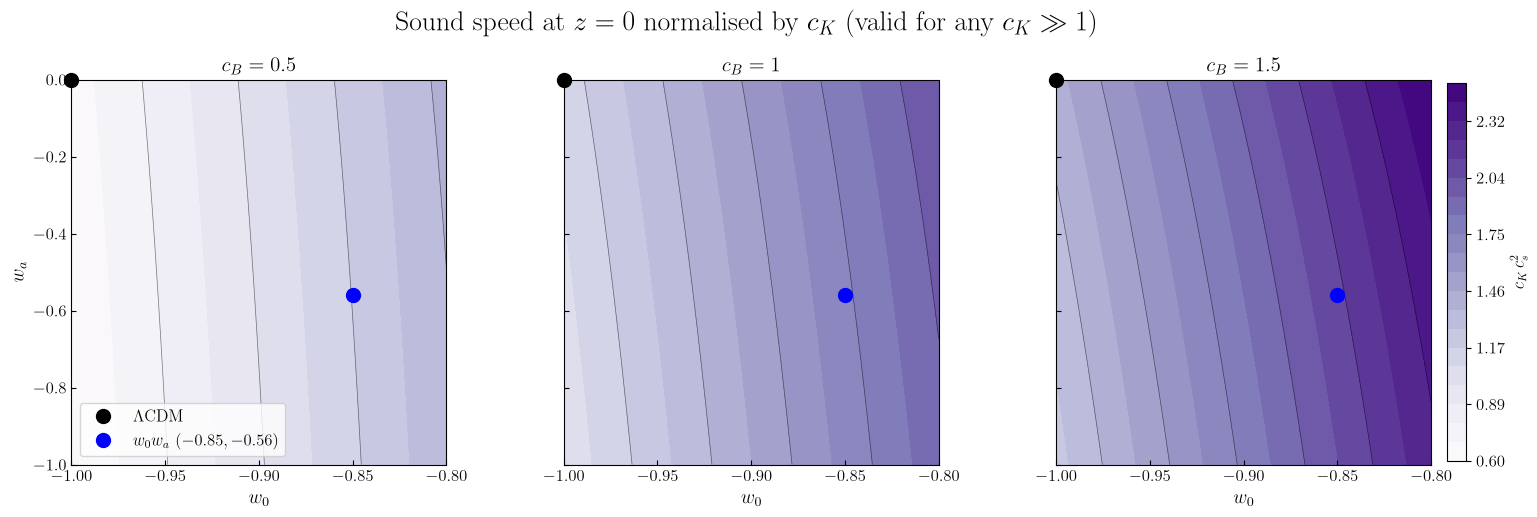

In [18]:
# Normalised sound speed: cK * cs2 only depends on cB and on the background
cs2_maps = {cb: np.full((len(WA), len(W0)), np.nan) for cb in CB_VALUES}
for (w0, wa), bg in backgrounds.items():
    i, j = np.where(WA == wa)[0][0], np.where(W0 == w0)[0][0]
    for cb in CB_VALUES:
        cs2_maps[cb][i, j] = CK * Horndeski(CK, cb, bg, PARAMETRIZATION).cs2()

fig, axs = plt.subplots(1, len(CB_VALUES), figsize=(6*len(CB_VALUES), 5), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.2)

# Common colour scale for the three panels
cs2_all = np.concatenate([m.ravel() for m in cs2_maps.values()])
levels_cs2 = np.linspace(np.nanmin(cs2_all), np.nanmax(cs2_all), 21)
for col, cb in enumerate(CB_VALUES):
    ax = axs[col]
    contour = ax.contourf(W0_grid, WA_grid, cs2_maps[cb], levels=levels_cs2, cmap='Purples', alpha=1)
    ax.contour(W0_grid, WA_grid, cs2_maps[cb], levels=levels_cs2[::2], colors='k', linewidths=0.5, alpha=0.5)
    # same colorbar space in every panel so they keep the same width; only the last one is shown
    cbar = plt.colorbar(contour, ax=ax, fraction=0.046, pad=0.04, format='%.2f')
    cbar.set_label(r'$c_K\, c_s^2$')
    cbar.ax.set_visible(col == len(CB_VALUES) - 1)

    ax.plot(-1, 0, marker='o', color='k', markersize=10, linestyle='none', label=r'$\Lambda$CDM', clip_on=False, zorder=5)
    ax.plot(-0.85, -0.56, marker='o', color='b', markersize=10, linestyle='none', label=r'$w_0w_a$ $(-0.85, -0.56)$', clip_on=False, zorder=5)
    ax.set_title(fr'$c_B = {cb:g}$', fontsize=15)
    ax.set_xlabel(r'$w_0$', fontsize=14)
    ax.tick_params(axis='both', which='both', direction='in')

axs[0].set_ylabel(r'$w_a$', fontsize=14)
axs[0].legend(loc='lower left')
fig.suptitle(r'Sound speed at $z=0$ normalised by $c_K$ (valid for any $c_K \gg 1$)', fontsize=20, y=1.02)